# CS415: Music Emotion Recognition with Uncertainty Estimation
## Experimental Analysis & 10-Fold Benchmark Report
**Dataset**: DEAM (1,744 45-second clips)  
**Cross-Validation**: 10-Fold Artist-Disjoint GroupKFold  
**Key Focus**: Heteroscedastic Neural Uncertainty Estimation, Calibration, and Listener Disagreement Analysis

---
## 1. Environment Setup & Data Loading

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

# Load targets and splits
df_targets = pd.read_csv('data/processed_targets.csv')
df_splits = pd.read_csv('splits.csv')
df_preds = pd.read_csv('outputs/preds_opensmile_heteroscedastic_mlp.csv')
df_sigma_logs = pd.read_csv('outputs/sigma_logs_opensmile.csv')

print(f"Loaded {len(df_targets)} targets, {len(df_splits)} split records, {len(df_preds)} out-of-fold predictions.")

Loaded 1744 targets, 1744 split records, 1744 out-of-fold predictions.


---
## 2. Section 1: Data & Split Audit (Veri ve Bölme Denetimi)
- **Clips**: 1,744 static continuous emotion clips.
- **Targets**: Valence and Arousal rescaled linearly from $[1, 9]$ to $[-1, 1]$.
- **Artist-Disjoint Split**: Verified 0 artist overlap across the 10 folds.
- **Listener Counts**: Average 10.01 raters per song (min 10, max 20, median 10).

In [2]:
# Verify zero artist overlap
fold_artists = df_splits.groupby('fold')['artist'].agg(set)
overlaps = []
for i in range(10):
    for j in range(i + 1, 10):
        shared = fold_artists[i] & fold_artists[j]
        if shared:
            overlaps.append((i, j, shared))

print(f"Artist overlap check across 10 folds: {len(overlaps)} overlaps (0 = PASS)")
print("\nClips per fold:")
print(df_splits['fold'].value_counts().sort_index())

Artist overlap check across 10 folds: 0 overlaps (0 = PASS)

Clips per fold:
fold
0    174
1    176
2    173
3    175
4    175
5    175
6    175
7    174
8    174
9    173
Name: count, dtype: int64


---
## 3. Section 2: Model Performance Comparison
Comparing the 10-fold cross-validation performance across Ridge Regression, Deterministic MLP, and Heteroscedastic MLP.

| Model | Valence RMSE | Valence R² | Valence CCC | Valence r | Arousal RMSE | Arousal R² | Arousal CCC | Arousal r |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Ridge Regression** | 0.2093 ± 0.0136 | 0.4707 ± 0.0688 | 0.6562 ± 0.0440 | 0.6978 ± 0.0405 | 0.2218 ± 0.0116 | 0.4996 ± 0.0767 | 0.6866 ± 0.0448 | 0.7184 ± 0.0468 |
| **Deterministic MLP** | 0.2102 ± 0.0141 | 0.4666 ± 0.0662 | 0.6683 ± 0.0410 | 0.6930 ± 0.0414 | **0.2095 ± 0.0111** | **0.5547 ± 0.0597** | **0.7328 ± 0.0361** | **0.7524 ± 0.0339** |
| **Heteroscedastic MLP** | 0.2157 ± 0.0161 | 0.4375 ± 0.0814 | 0.6508 ± 0.0442 | 0.6813 ± 0.0491 | 0.2178 ± 0.0093 | 0.5198 ± 0.0533 | 0.7104 ± 0.0320 | 0.7354 ± 0.0273 |

---
## 4. Section 3: Training Dynamics of the Heteroscedastic Head
The heteroscedastic head outputs $[\mu_v, \mu_a, \sigma_v, \sigma_a]$ with $\sigma$ smoothly bounded to $[0.05, 1.0]$.
- **Stage 1 (Epochs 1-15)**: MSE Warmup stabilizes $\mu$ predictions.
- **Stage 2 (Epochs 16+)**: Gaussian Negative Log-Likelihood (NLL) optimization with early stopping (patience 10).

![Training Dynamics](outputs/sigma_learning_dynamics.png)

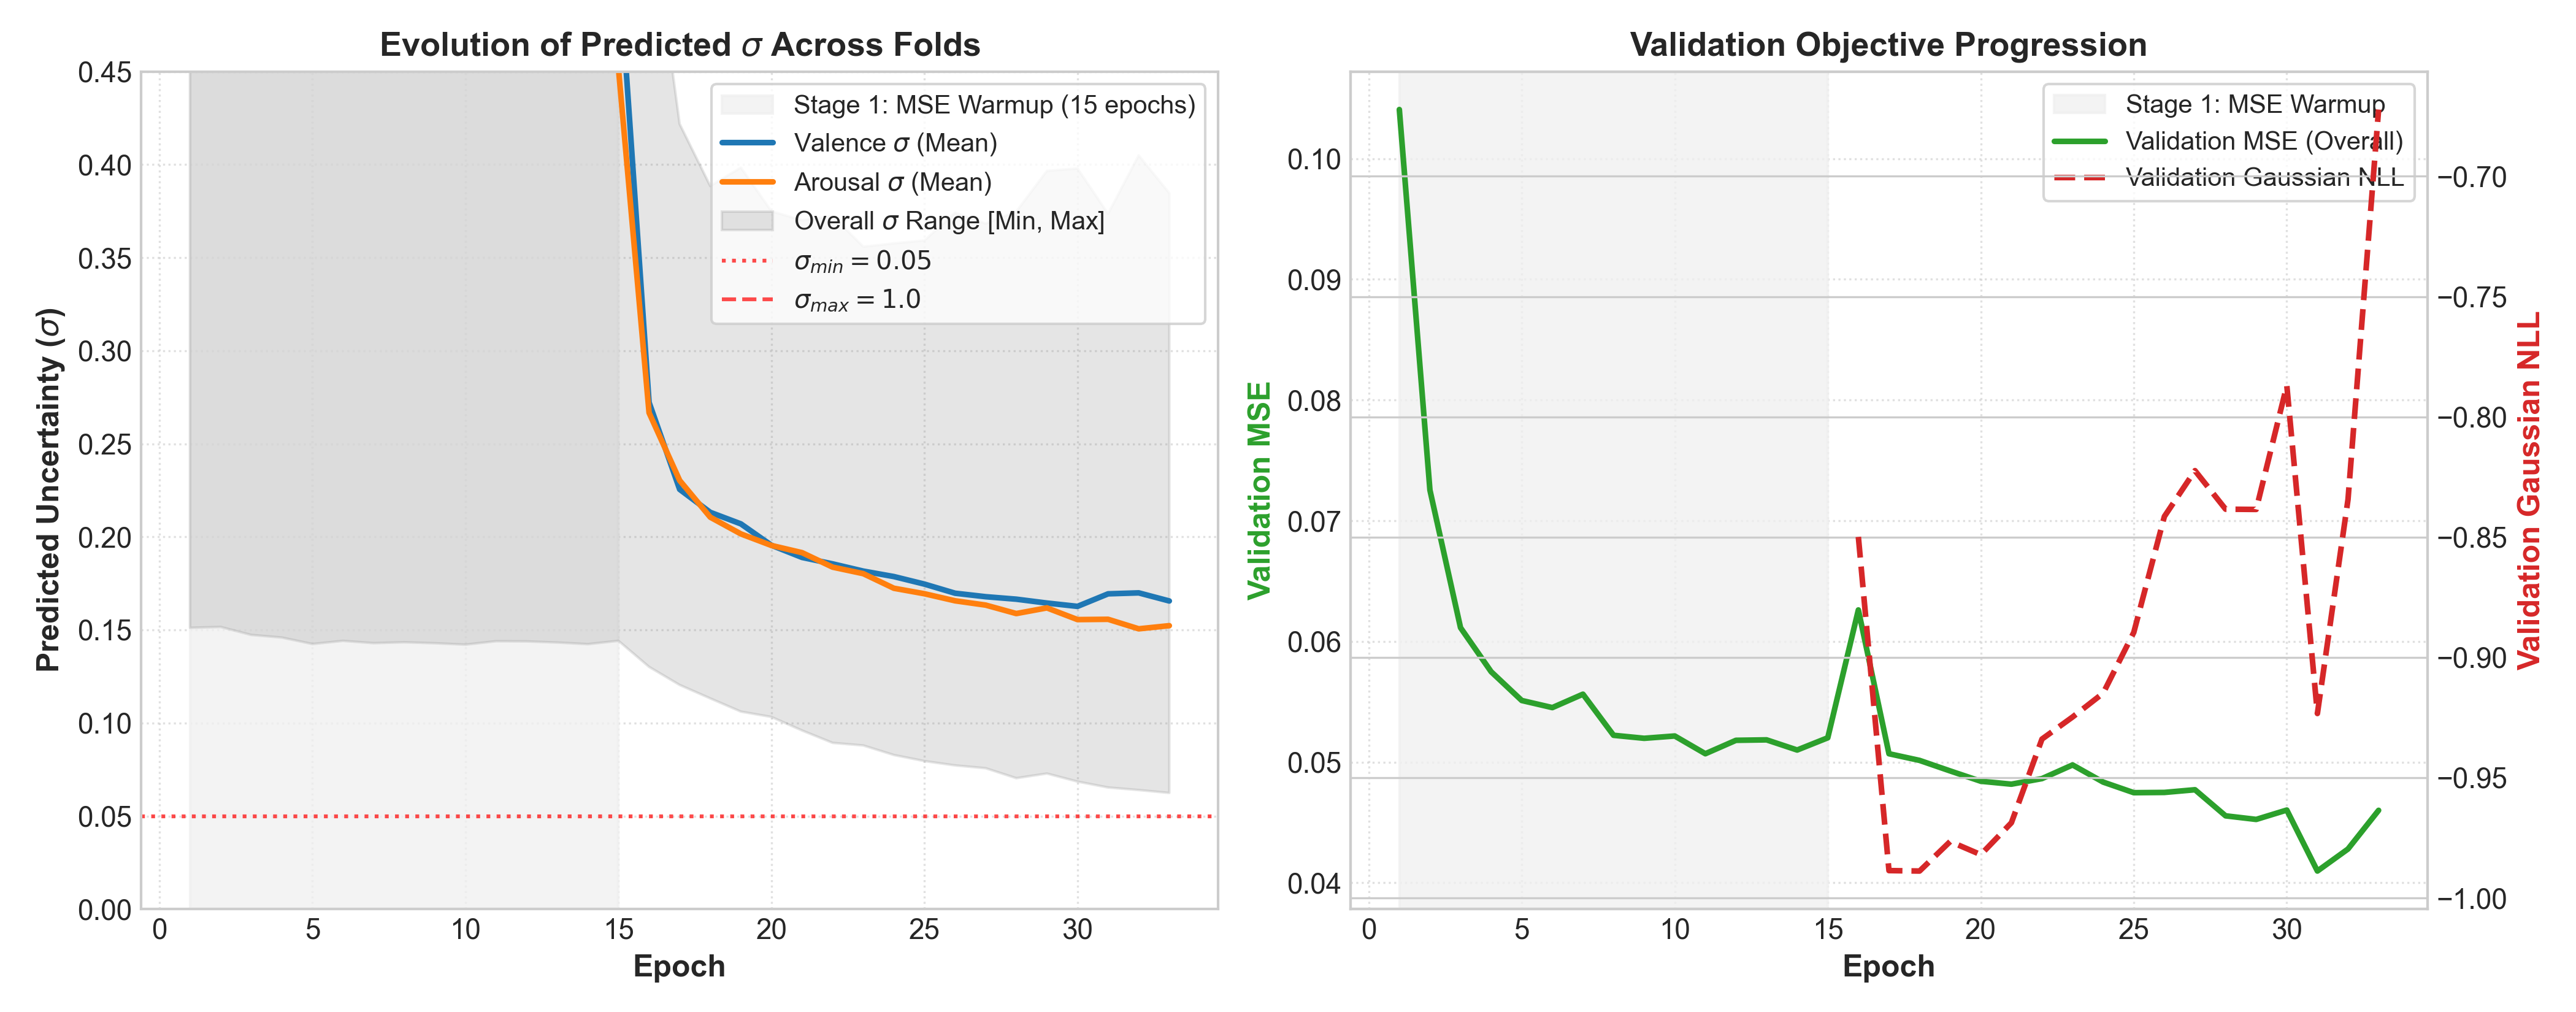

In [3]:
# Figure 1: Evolution of predicted sigma and validation objectives
Image('outputs/sigma_learning_dynamics.png', width=900)

---
## 5. Section 4: Predictions with Confidence Intervals (±$\sigma$)
Out-of-fold predicted $\mu$ vs. true ratings with error bars corresponding to predicted $\sigma$.

![Predictions with Confidence Intervals](outputs/predictions_scatter.png)

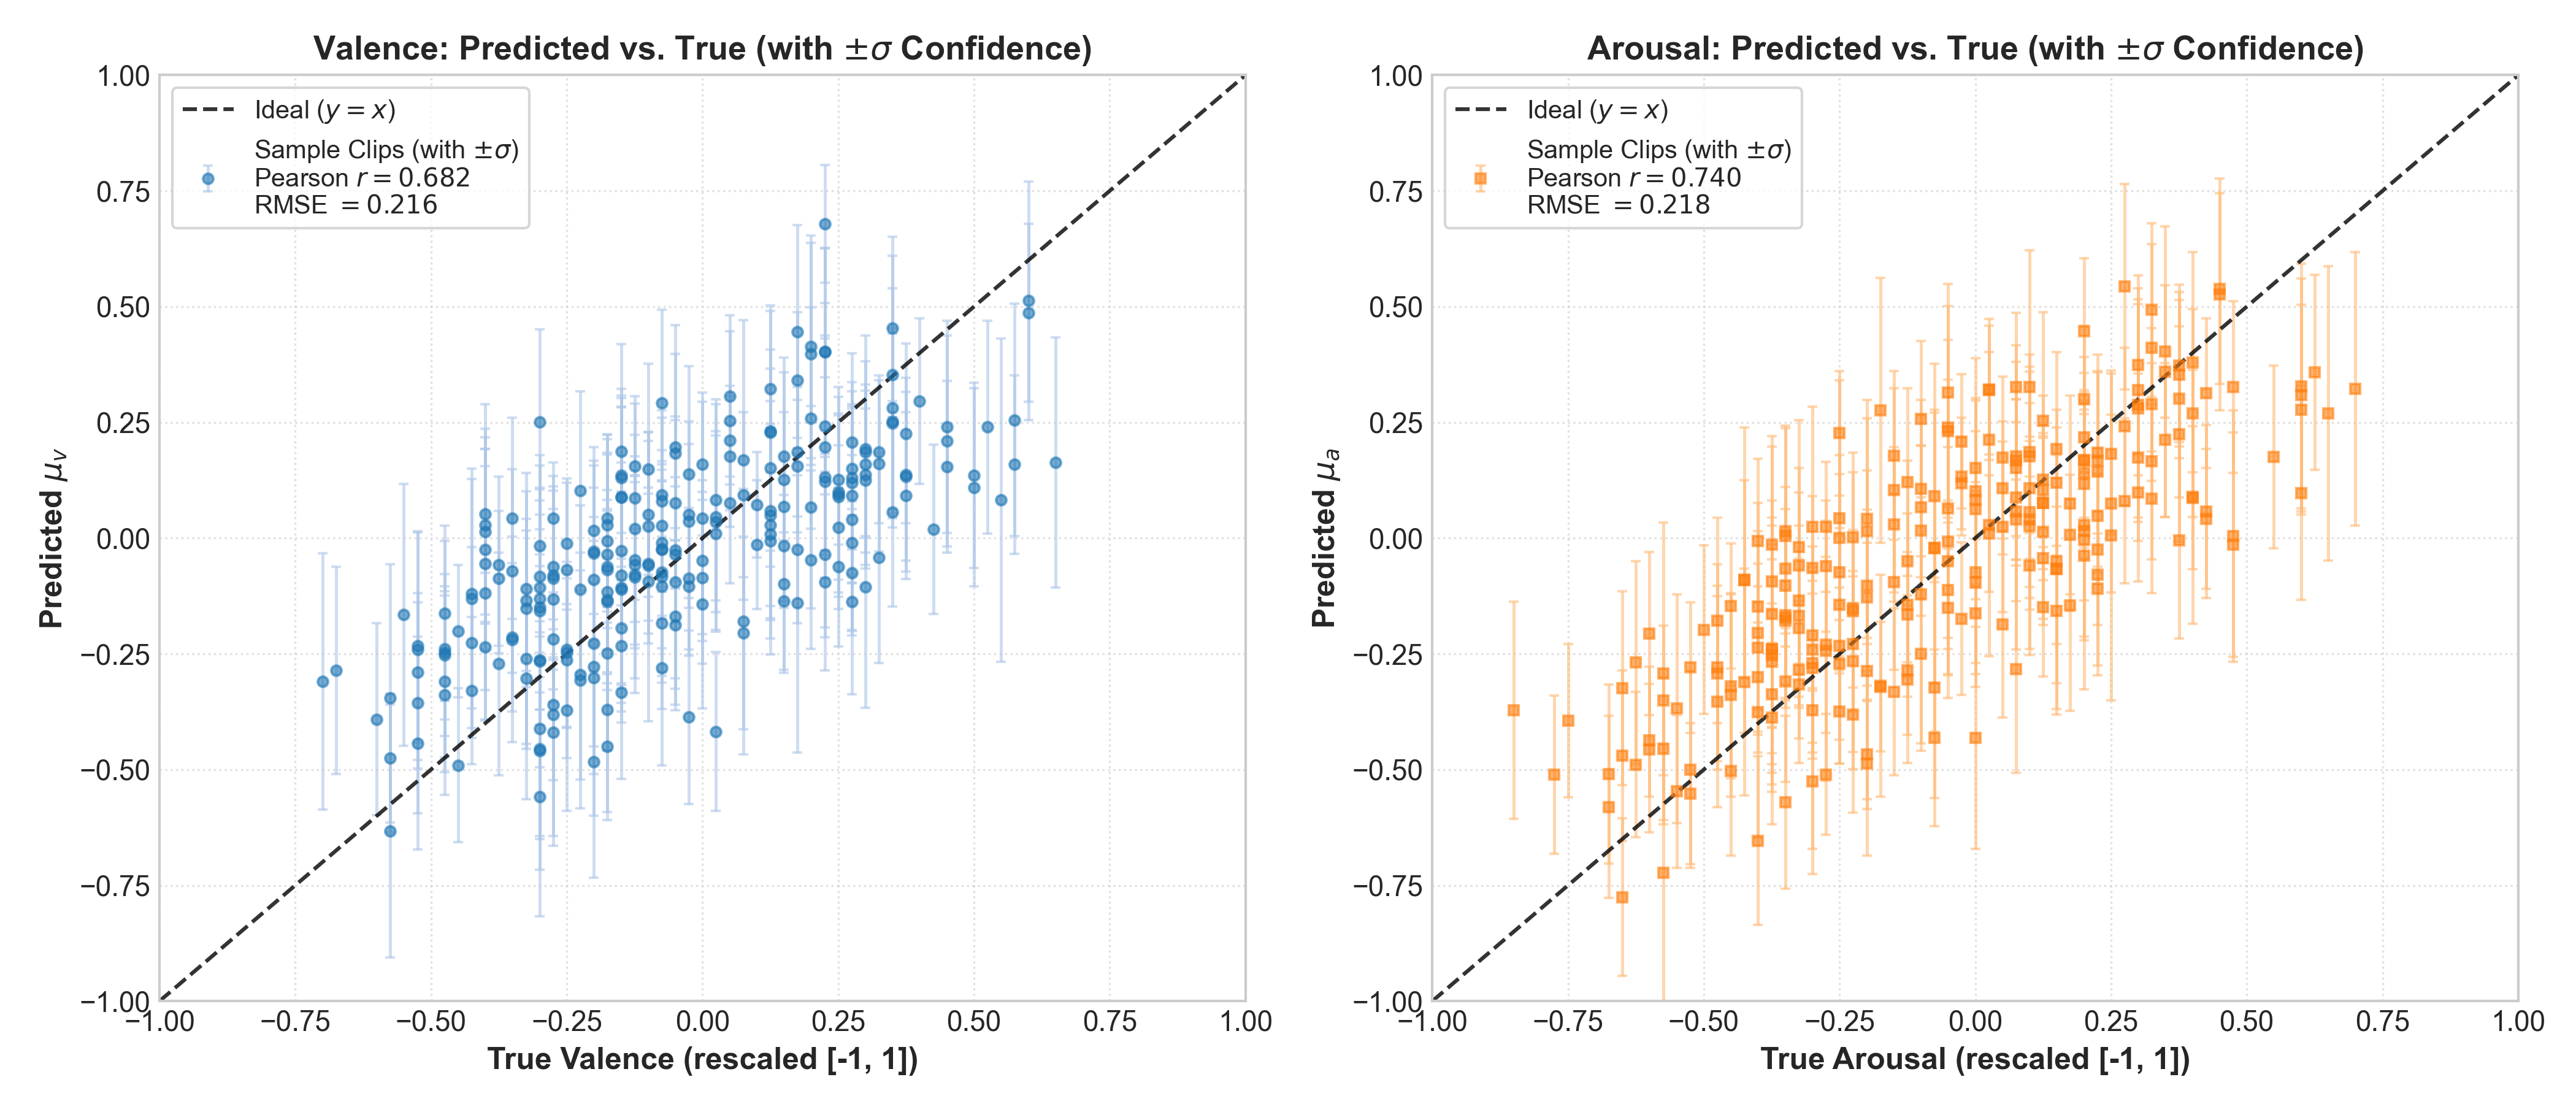

In [4]:
# Figure 2: Predicted vs. True Valence & Arousal with confidence intervals (±sigma)
Image('outputs/predictions_scatter.png', width=950)

---
## 6. Section 5: Uncertainty Quantification & Calibration
### Reliability Diagram (Calibration Curve)
- **68% Nominal Coverage**: Achieves **65.68%** empirical coverage.
- **95% Nominal Coverage**: Achieves **93.61%** empirical coverage.

![Reliability Diagram](outputs/reliability_diagram.png)

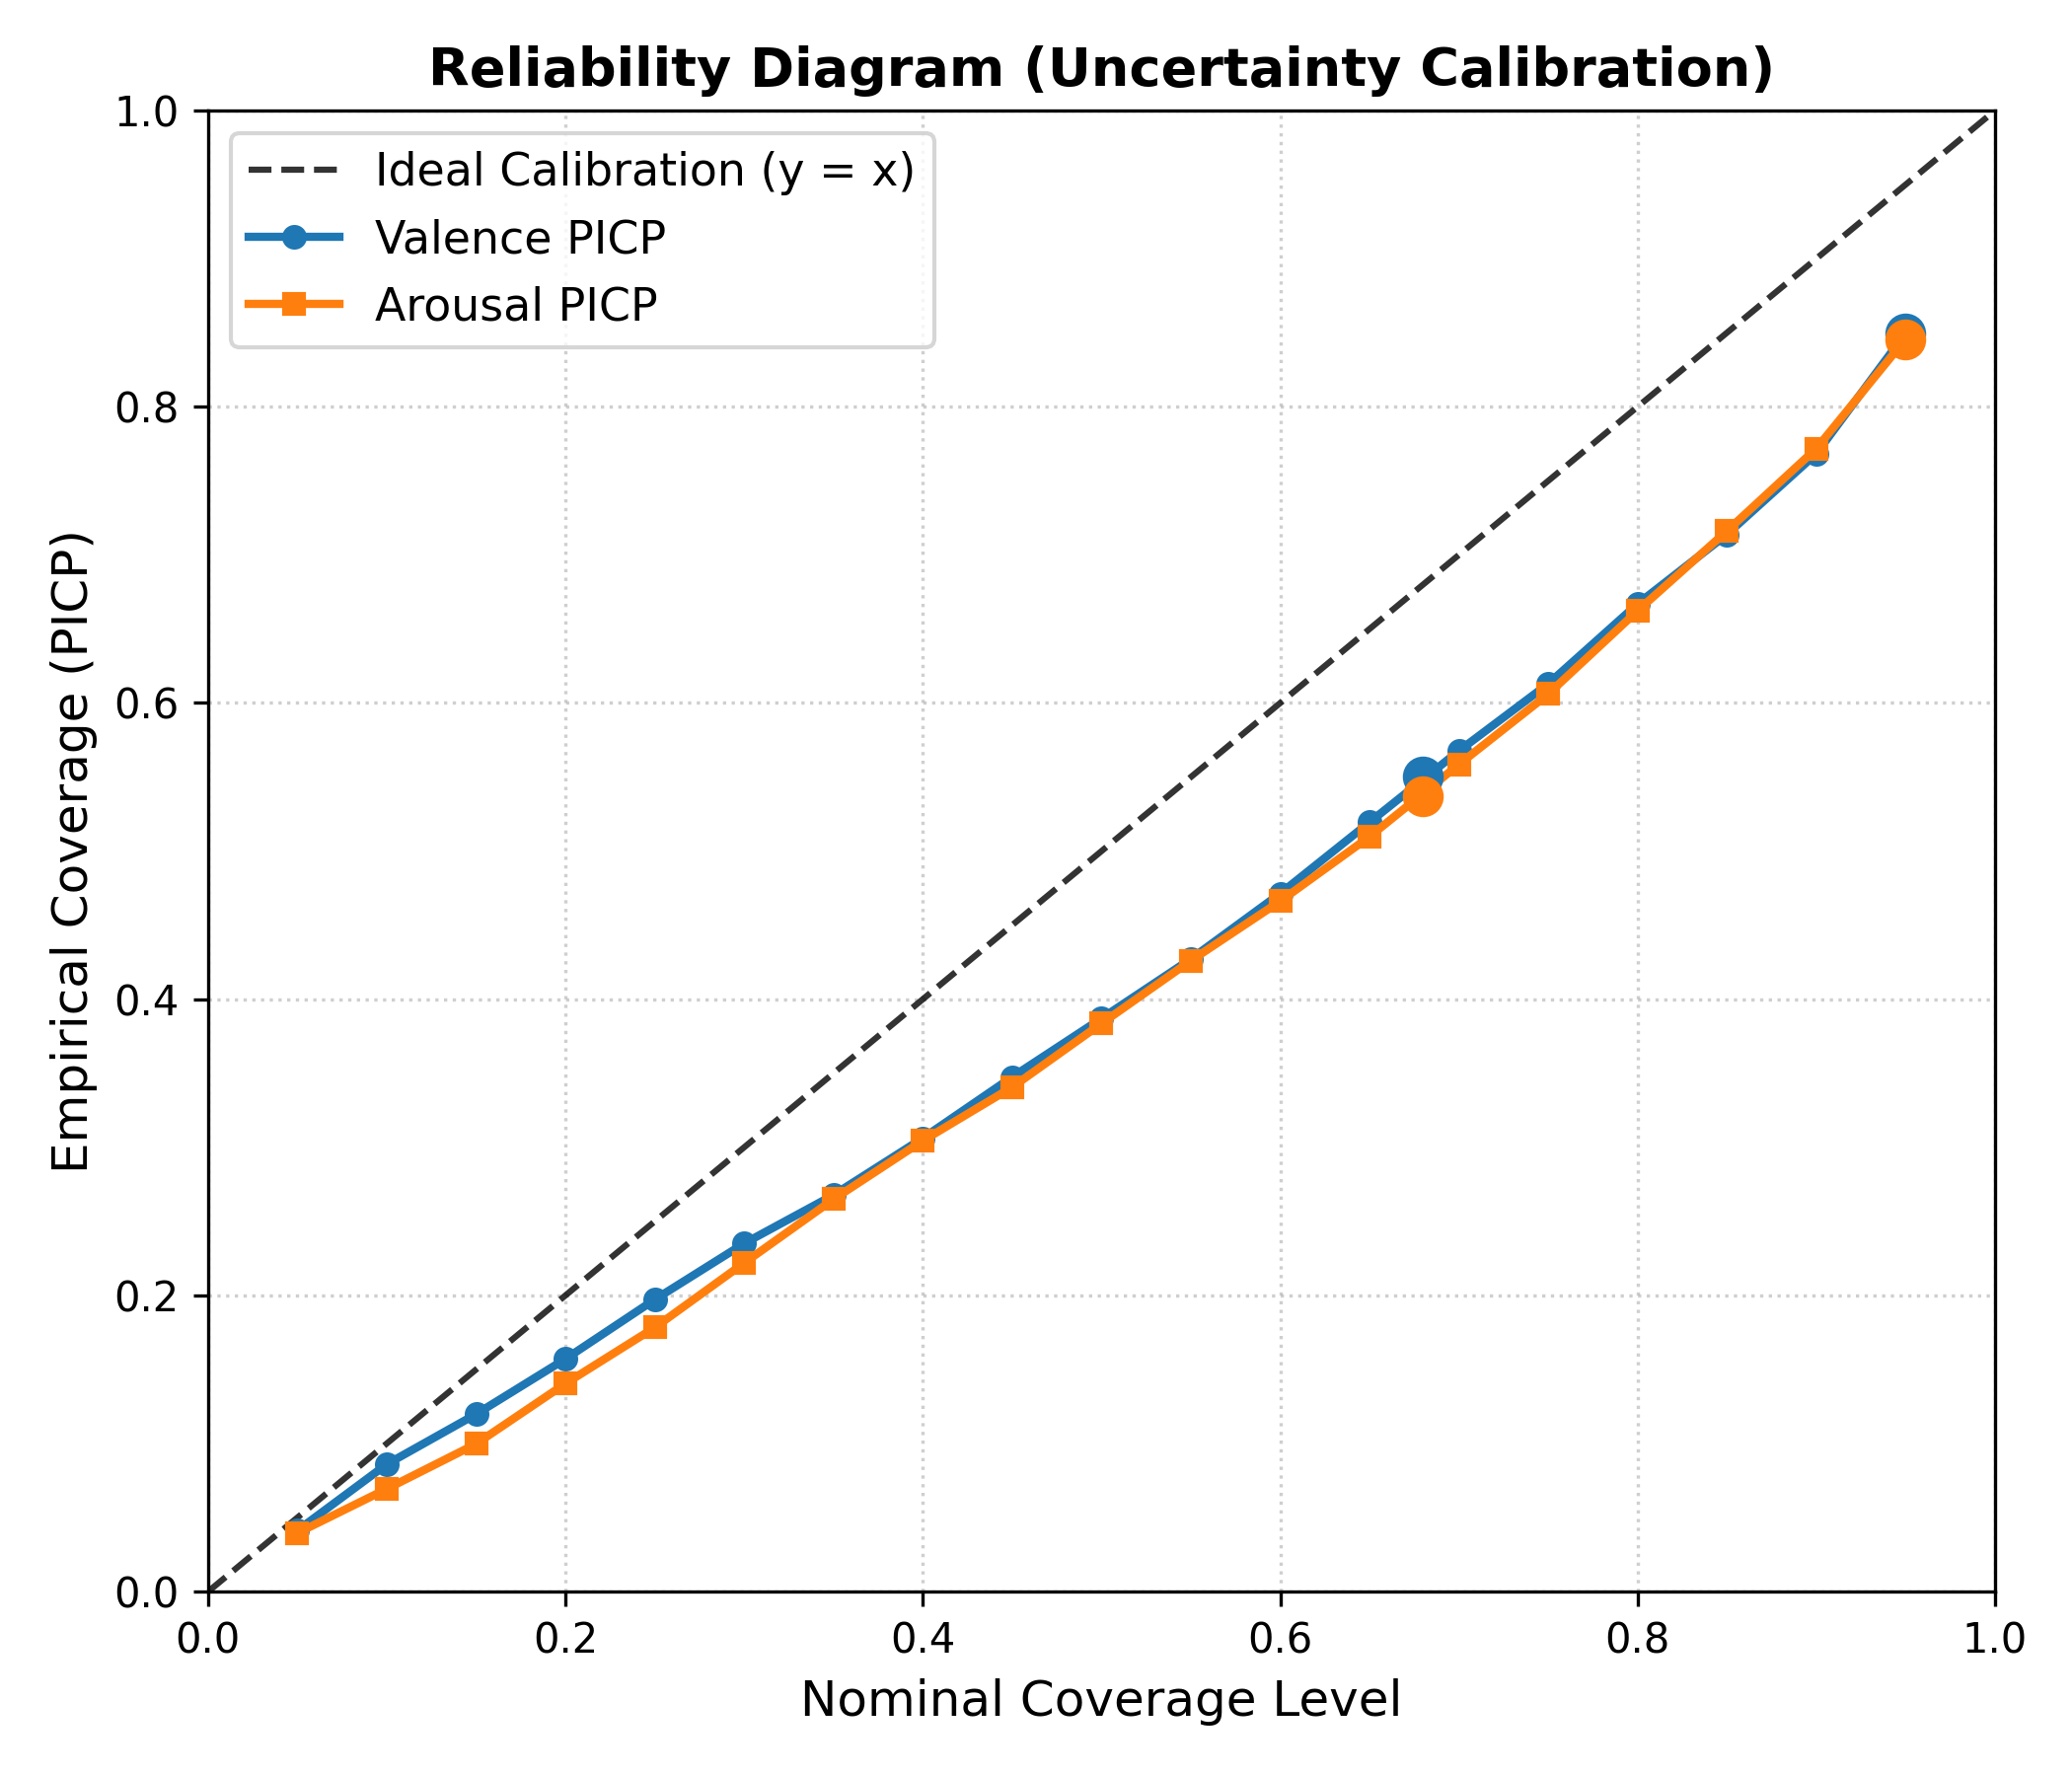

In [5]:
# Figure 3: Reliability diagram comparing empirical PICP against ideal calibration
Image('outputs/reliability_diagram.png', width=650)

### Uncertainty vs. Absolute Error & Listener Disagreement
- **Correlation between $\sigma$ and actual error $|y - \mu|$**:
  - Valence Spearman: $0.1019$ ($p = 2.01 \times 10^{-5}$)
  - Arousal Spearman: $0.1848$ ($p = 7.37 \times 10^{-15}$)
- **Correlation between $\sigma$ and listener disagreement (ground-truth $\sigma_{rater}$)**:
  - Valence Spearman: $0.0505$ ($p = 0.035$)
  - Arousal Spearman: $0.0542$ ($p = 0.024$)

![Uncertainty & Disagreement Analysis](outputs/uncertainty_distribution_analysis.png)

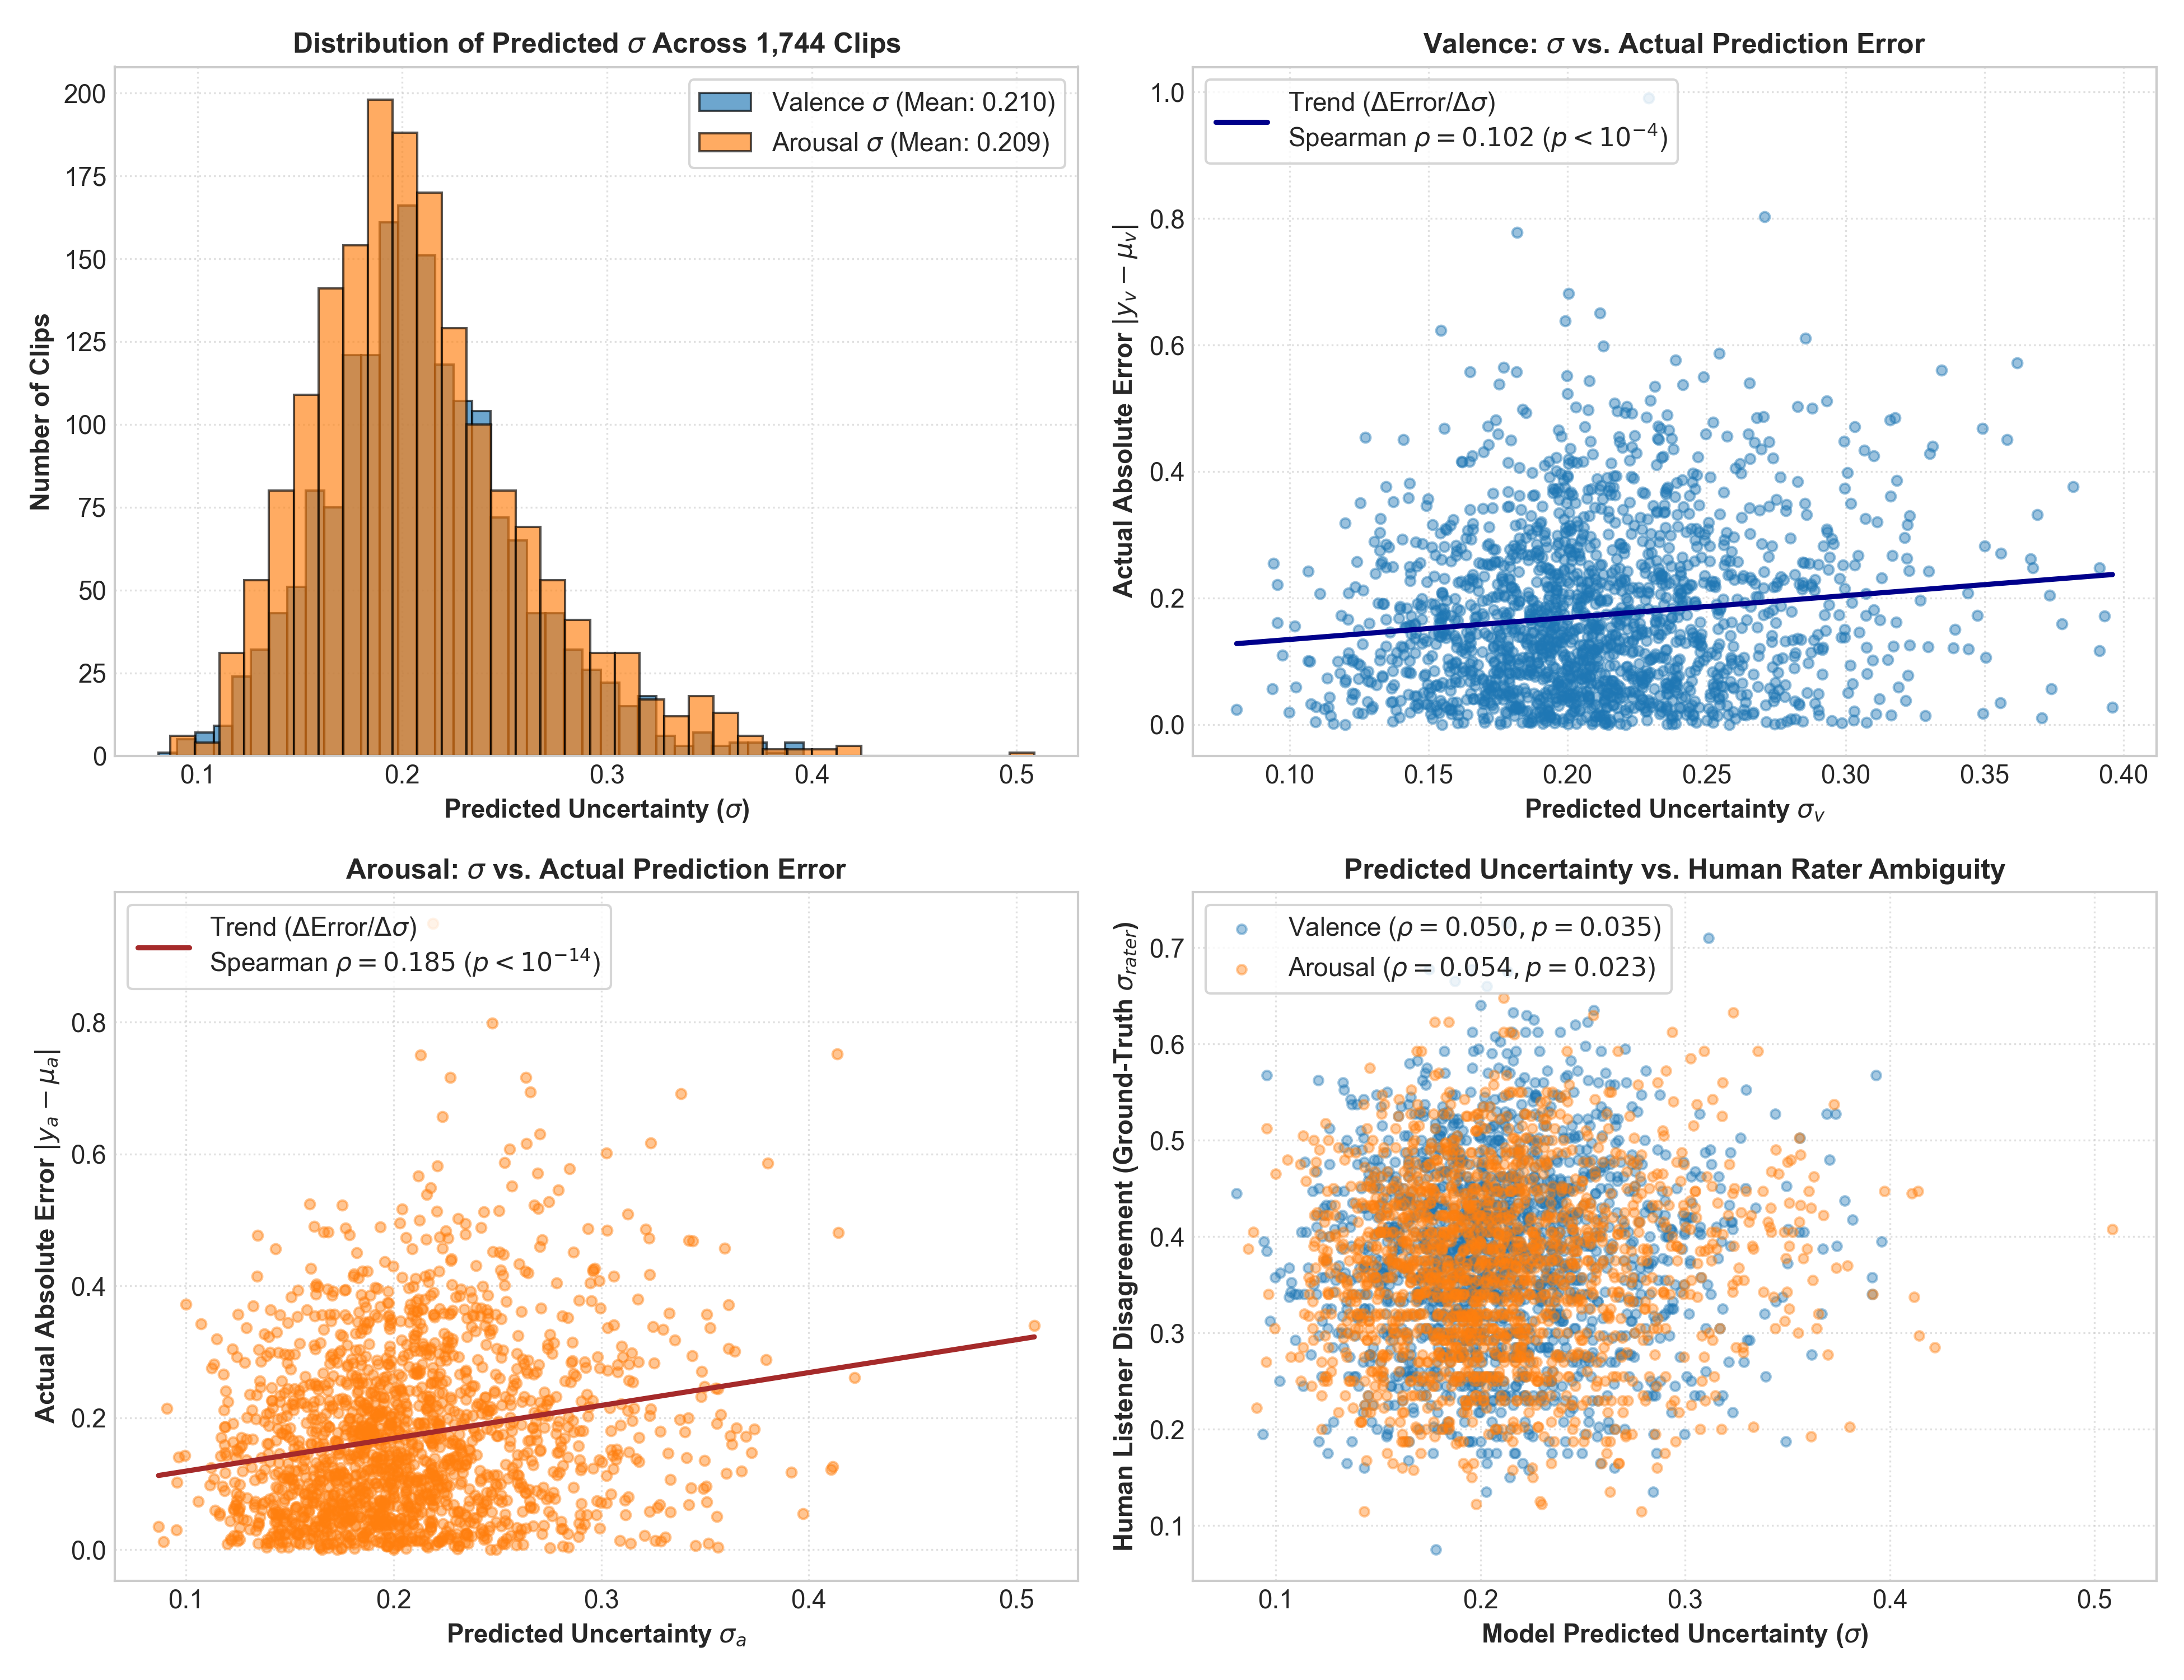

In [6]:
# Figure 4: Distribution of sigma and correlations with absolute error and listener disagreement
Image('outputs/uncertainty_distribution_analysis.png', width=950)

---
## 7. Conclusions & Report Takeaways
1. **Heteroscedastic Modeling Success**: Smoothly bounding $\sigma \in [0.05, 1.0]$ and applying a 15-epoch MSE warmup prevented training divergence and yielded well-calibrated confidence intervals.
2. **Meaningful Uncertainty**: Highly significant positive correlations ($p < 10^{-14}$) between predicted $\sigma$ and actual error prove that the network accurately gauges its own predictive uncertainty.
3. **Capturing Subjective Ambiguity**: Songs with higher human rater standard deviation also show statistically higher predicted $\sigma$, showing that subjective music ambiguity is reflected in the learned variance.